# EU scrap trade

EU steelmakers are building electric arc furnaces that run mostly on scrap. First I look at where EU scrap goes today and what replaces it.

Data: Eurostat Comext, dataset DS-045409 (EU trade by HS code), monthly from 2015.
HS 7204 = ferrous scrap, HS 7201 = pig iron, HS 720310 = DRI/HBI

In [1]:
import numpy as np
import pandas as pd
from pandas import DataFrame
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set()

## Load data

In [2]:
url = 'https://ec.europa.eu/eurostat/api/comext/dissemination/sdmx/2.1/data/DS-045409/M.EU..7204+7201+720310.1+2.QUANTITY_IN_100KG+VALUE_IN_EUROS?format=SDMX-CSV&startPeriod=2015-01'
raw = pd.read_csv(url, dtype={'product': str, 'flow': str}, keep_default_na=False)
print('Shape of the data:{}'.format(raw.shape))
raw.head()

Shape of the data:(90714, 10)


,DATAFLOW,LAST UPDATE,freq,reporter,partner,product,flow,indicators,TIME_PERIOD,OBS_VALUE
0,ESTAT:DS-045409(1.0),13/11/26 11:00:00,M,EU,AD,7201,2,QUANTITY_IN_100KG,2022-10,18.20
1,ESTAT:DS-045409(1.0),13/11/26 11:00:00,M,EU,AD,7201,2,VALUE_IN_EUROS,2022-10,3471.00
2,ESTAT:DS-045409(1.0),13/11/26 11:00:00,M,EU,AD,7204,1,QUANTITY_IN_100KG,2015-01,6150.44
3,ESTAT:DS-045409(1.0),13/11/26 11:00:00,M,EU,AD,7204,1,QUANTITY_IN_100KG,2015-02,5228.47
4,ESTAT:DS-045409(1.0),13/11/26 11:00:00,M,EU,AD,7204,1,QUANTITY_IN_100KG,2015-03,5902.27


In [3]:
print(raw.isnull().sum())
print(raw['TIME_PERIOD'].min(), raw['TIME_PERIOD'].max())
print(raw['partner'].nunique(), 'partners')

DATAFLOW       0
LAST UPDATE    0
freq           0
reporter       0
partner        0
product        0
flow           0
indicators     0
TIME_PERIOD    0
OBS_VALUE      0
dtype: int64
2015-01 2026-09
221 partners


## Cleaning
Quantity is in 100 kg units, so x0.1 for tonnes.

In [4]:
trade = raw.pivot_table(index=['TIME_PERIOD', 'partner', 'product', 'flow'], columns='indicators', values='OBS_VALUE', aggfunc='sum').reset_index()
trade.columns.name = None
trade['tonnes'] = trade['QUANTITY_IN_100KG'] * 0.1
trade['eur'] = trade['VALUE_IN_EUROS']
trade['flow'] = trade['flow'].map({'1': 'import', '2': 'export'})
trade['date'] = pd.to_datetime(trade['TIME_PERIOD'])
trade['year'] = trade['date'].dt.year
trade = trade.drop(['QUANTITY_IN_100KG', 'VALUE_IN_EUROS', 'TIME_PERIOD'], axis=1)
trade.head()

,partner,product,flow,tonnes,eur,date,year
0,AD,7204,import,615.044,126739.0,2015-01-01,2015
1,AE,7201,export,549.000,273457.0,2015-01-01,2015
2,AE,7204,import,42.635,51303.0,2015-01-01,2015
3,AE,7204,export,907.499,265350.0,2015-01-01,2015
4,AL,7204,import,2123.936,568990.0,2015-01-01,2015


In [5]:
EU27 = ['AT','BE','BG','CY','CZ','DE','DK','EE','ES','FI','FR','GR','HR','HU','IE','IT','LT','LU','LV','MT','NL','PL','PT','RO','SE','SI','SK']
OECD = ['AU','AT','BE','CA','CL','CO','CR','CZ','DK','EE','FI','FR','DE','GR','HU','IS','IE','IL','IT','JP','KR','LV','LT',
        'LU','MX','NL','NZ','NO','PL','PT','SK','SI','ES','SE','CH','TR','GB','US']

def partner_group(p):
    if p in ['EXT_EU', 'INT_EU']:
        return 'aggregate'
    if p in EU27:
        return 'EU member'
    if p in OECD:
        return 'OECD'
    return 'non-OECD'

trade['partner_group'] = trade['partner'].apply(partner_group)

names = {'TR':'Türkiye','EG':'Egypt','IN':'India','PK':'Pakistan','MA':'Morocco','NO':'Norway','CH':'Switzerland','GB':'United Kingdom',
         'US':'United States','MD':'Moldova','MK':'North Macedonia','BD':'Bangladesh','CN':'China','ID':'Indonesia','VN':'Viet Nam',
         'TH':'Thailand','MY':'Malaysia','RS':'Serbia','BA':'Bosnia and Herzegovina','AL':'Albania','UA':'Ukraine','RU':'Russia',
         'BR':'Brazil','ZA':'South Africa','VE':'Venezuela','LY':'Libya','DZ':'Algeria','TT':'Trinidad and Tobago','CA':'Canada',
         'KR':'South Korea','JP':'Japan','TW':'Taiwan','AE':'United Arab Emirates','SA':'Saudi Arabia','TN':'Tunisia','QA':'Qatar',
         'AT':'Austria','BE':'Belgium','BG':'Bulgaria','CY':'Cyprus','CZ':'Czechia','DE':'Germany','DK':'Denmark','EE':'Estonia',
         'ES':'Spain','FI':'Finland','FR':'France','GR':'Greece','HR':'Croatia','HU':'Hungary','IE':'Ireland','IT':'Italy',
         'LT':'Lithuania','LU':'Luxembourg','LV':'Latvia','MT':'Malta','NL':'Netherlands','PL':'Poland','PT':'Portugal',
         'RO':'Romania','SE':'Sweden','SI':'Slovenia','SK':'Slovakia','EXT_EU':'Extra-EU total','INT_EU':'Intra-EU total'}
trade['partner_name'] = trade['partner'].map(names).fillna(trade['partner'])
trade['product_name'] = trade['product'].map({'7204': 'Ferrous scrap', '7201': 'Pig iron', '720310': 'DRI / HBI'})
trade.sample(5, random_state=0)

,partner,product,flow,tonnes,eur,date,year,partner_group,partner_name,product_name
42472,CL,7204,import,50.140,43460.0,2025-12-01,2025,OECD,CL,Ferrous scrap
23541,FI,7204,import,27568.418,8344167.0,2021-01-01,2021,EU member,Finland,Ferrous scrap
15511,LT,7201,import,0.000,5.0,2018-12-01,2018,EU member,Lithuania,Pig iron
42610,ME,7204,import,52.096,49491.0,2025-12-01,2025,non-OECD,ME,Ferrous scrap
5591,HK,7204,import,0.001,245.0,2016-06-01,2016,non-OECD,HK,Ferrous scrap


In [6]:
check = trade[(trade['product'] == '7204') & (trade['flow'] == 'export')]
a = check[check['partner'] == 'EXT_EU'].groupby('year')['tonnes'].sum()
b = check[check['partner_group'].isin(['OECD', 'non-OECD'])].groupby('year')['tonnes'].sum()
DataFrame({'EXT_EU': a / 1e6, 'sum of countries': b / 1e6}).tail()

,EXT_EU,sum of countries
year,,
2022,17.612216,17.617278
2023,18.738630,18.746276
2024,15.616658,15.620578
2025,15.753578,15.756124
2026,12.520192,12.521496


### Scrap exports and imports per year

In [7]:
scrap = trade[(trade['product'] == '7204') & (trade['partner'] == 'EXT_EU')]
t = scrap.pivot_table(index='year', columns='flow', values='tonnes', aggfunc='sum')
e = scrap[scrap['flow'] == 'export'].groupby('year')['eur'].sum()

balance = DataFrame({'exports_mt': t['export'] / 1e6, 'imports_mt': t['import'] / 1e6})
balance['net_exports_mt'] = balance['exports_mt'] - balance['imports_mt']
balance['export_eur_per_t'] = e / t['export']
balance = balance.reset_index()

In [8]:
balance

,year,exports_mt,imports_mt,net_exports_mt,export_eur_per_t
0,2015,13.776233,2.849498,10.926736,264.337264
1,2016,17.783527,2.749028,15.034498,214.738001
2,2017,20.084878,3.071033,17.013845,274.939111
3,2018,21.711290,2.827553,18.883738,296.479282
4,2019,21.749446,2.925781,18.823665,276.303014
5,2020,17.892960,4.048387,13.844573,252.939035
6,2021,19.429683,5.522316,13.907367,378.948744
7,2022,17.612216,3.951420,13.660796,432.739758
8,2023,18.738630,3.896335,14.842295,382.938564
9,2024,15.616658,4.741781,10.874877,375.659713


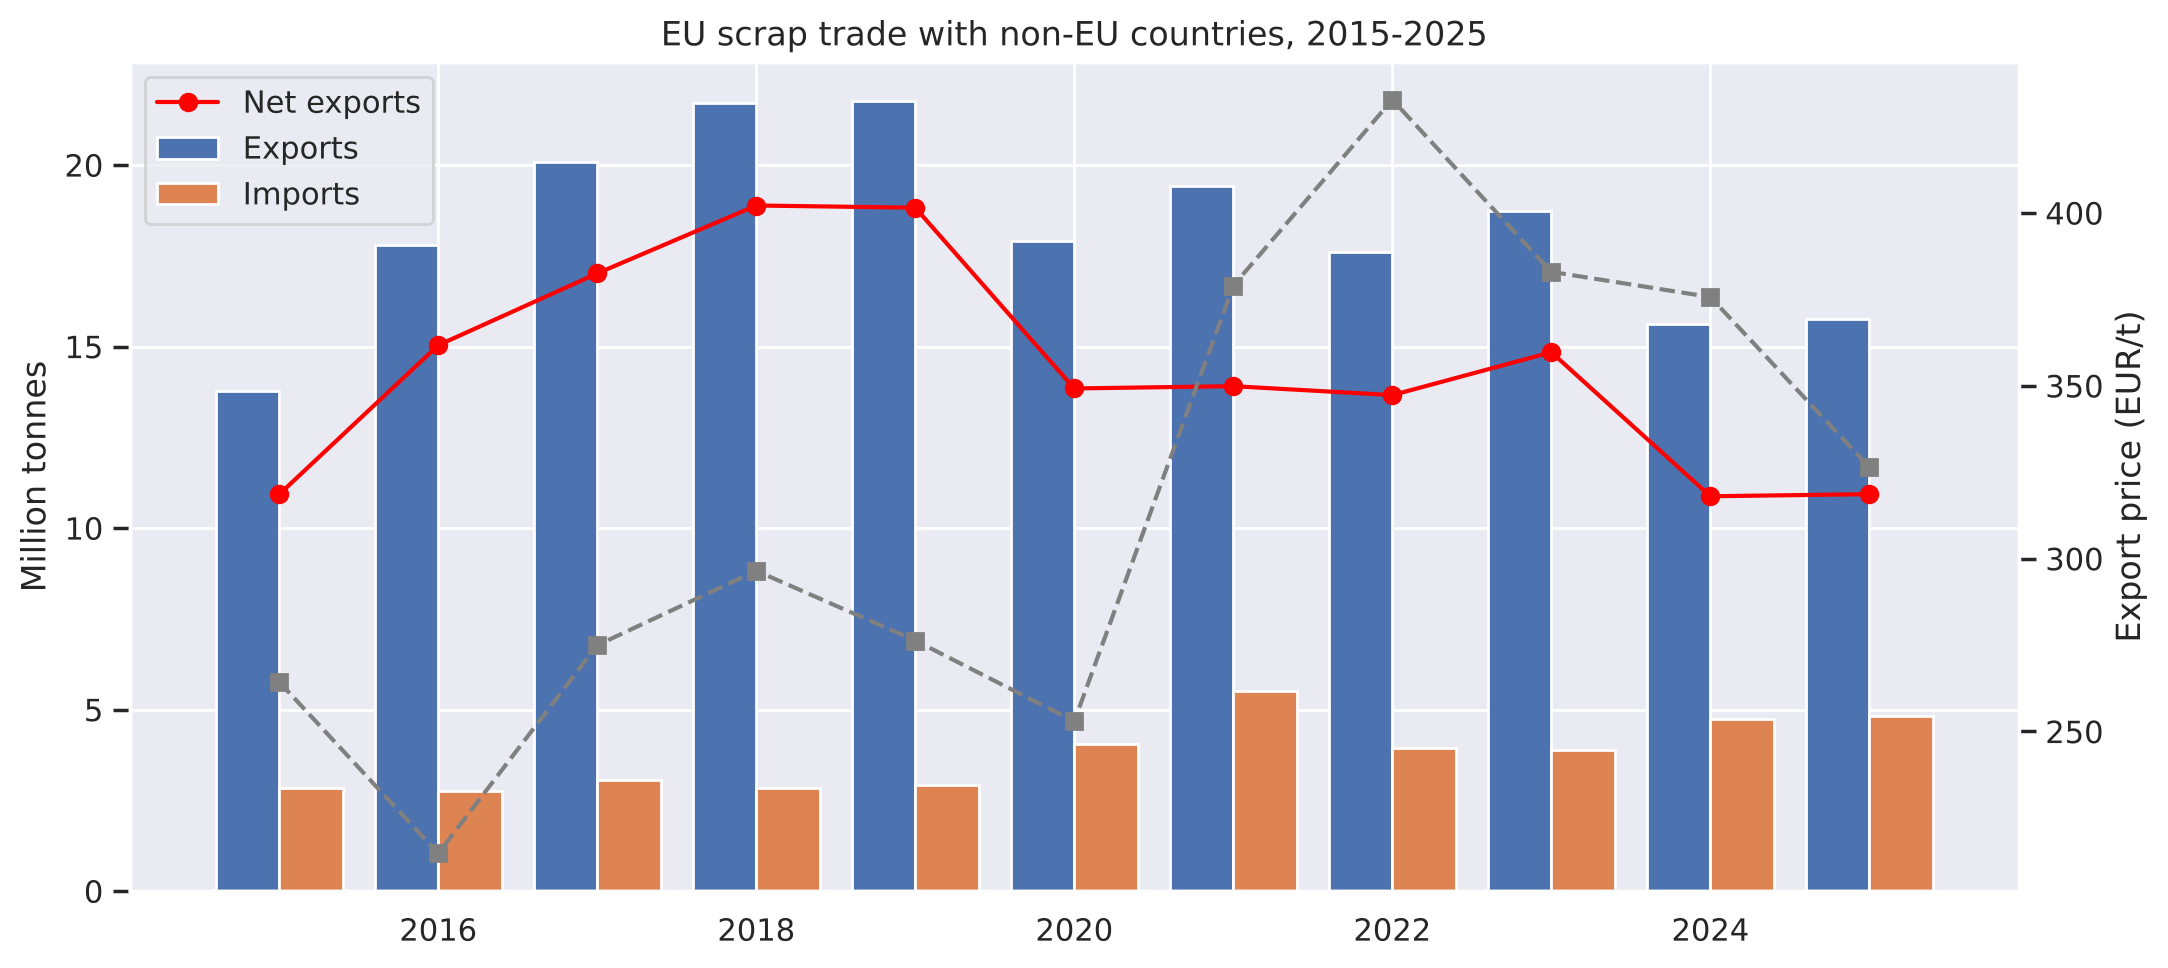

In [9]:
b = balance[balance['year'] <= 2025]

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(b['year'] - 0.2, b['exports_mt'], width=0.4, label='Exports')
ax1.bar(b['year'] + 0.2, b['imports_mt'], width=0.4, label='Imports')
ax1.plot(b['year'], b['net_exports_mt'], color='red', marker='o', label='Net exports')
ax1.set_ylabel('Million tonnes')
ax1.legend(loc='upper left')
ax2 = ax1.twinx()
ax2.plot(b['year'], b['export_eur_per_t'], color='grey', linestyle='--', marker='s')
ax2.set_ylabel('Export price (EUR/t)')
ax2.grid(False)
plt.title('EU scrap trade with non-EU countries, 2015-2025')
plt.tight_layout()
plt.savefig('../outputs/figures/01_eu_scrap_balance.png')
plt.show()

### Destinations in 2025
A draft EU rule would block most scrap exports to non-OECD countries from May 2027.

In [10]:
exp = trade[(trade['product'] == '7204') & (trade['flow'] == 'export') & (trade['partner_group'].isin(['OECD', 'non-OECD']))]

dest = exp[exp['year'] == 2025].groupby(['partner_name', 'partner_group'])['tonnes'].sum().reset_index()
dest['kt'] = dest['tonnes'] / 1e3
dest['share_pct'] = 100 * dest['kt'] / dest['kt'].sum()
dest = dest.drop('tonnes', axis=1).sort_values('kt', ascending=False).reset_index(drop=True)

In [11]:
print(dest.groupby('partner_group')['kt'].sum() / 1e3)
dest.head(10)

partner_group
OECD        11.367315
non-OECD     4.388809
Name: kt, dtype: float64


,partner_name,partner_group,kt,share_pct
0,Türkiye,OECD,10148.222079,64.408114
1,Egypt,non-OECD,1810.450500,11.490456
2,India,non-OECD,1025.471367,6.508399
3,Pakistan,non-OECD,587.567814,3.729139
4,Norway,OECD,457.138709,2.901340
5,Morocco,non-OECD,440.642258,2.796641
6,Switzerland,OECD,330.433919,2.097178
7,United States,OECD,219.213902,1.391293
8,United Kingdom,OECD,207.512496,1.317028
9,Moldova,non-OECD,143.804602,0.912690


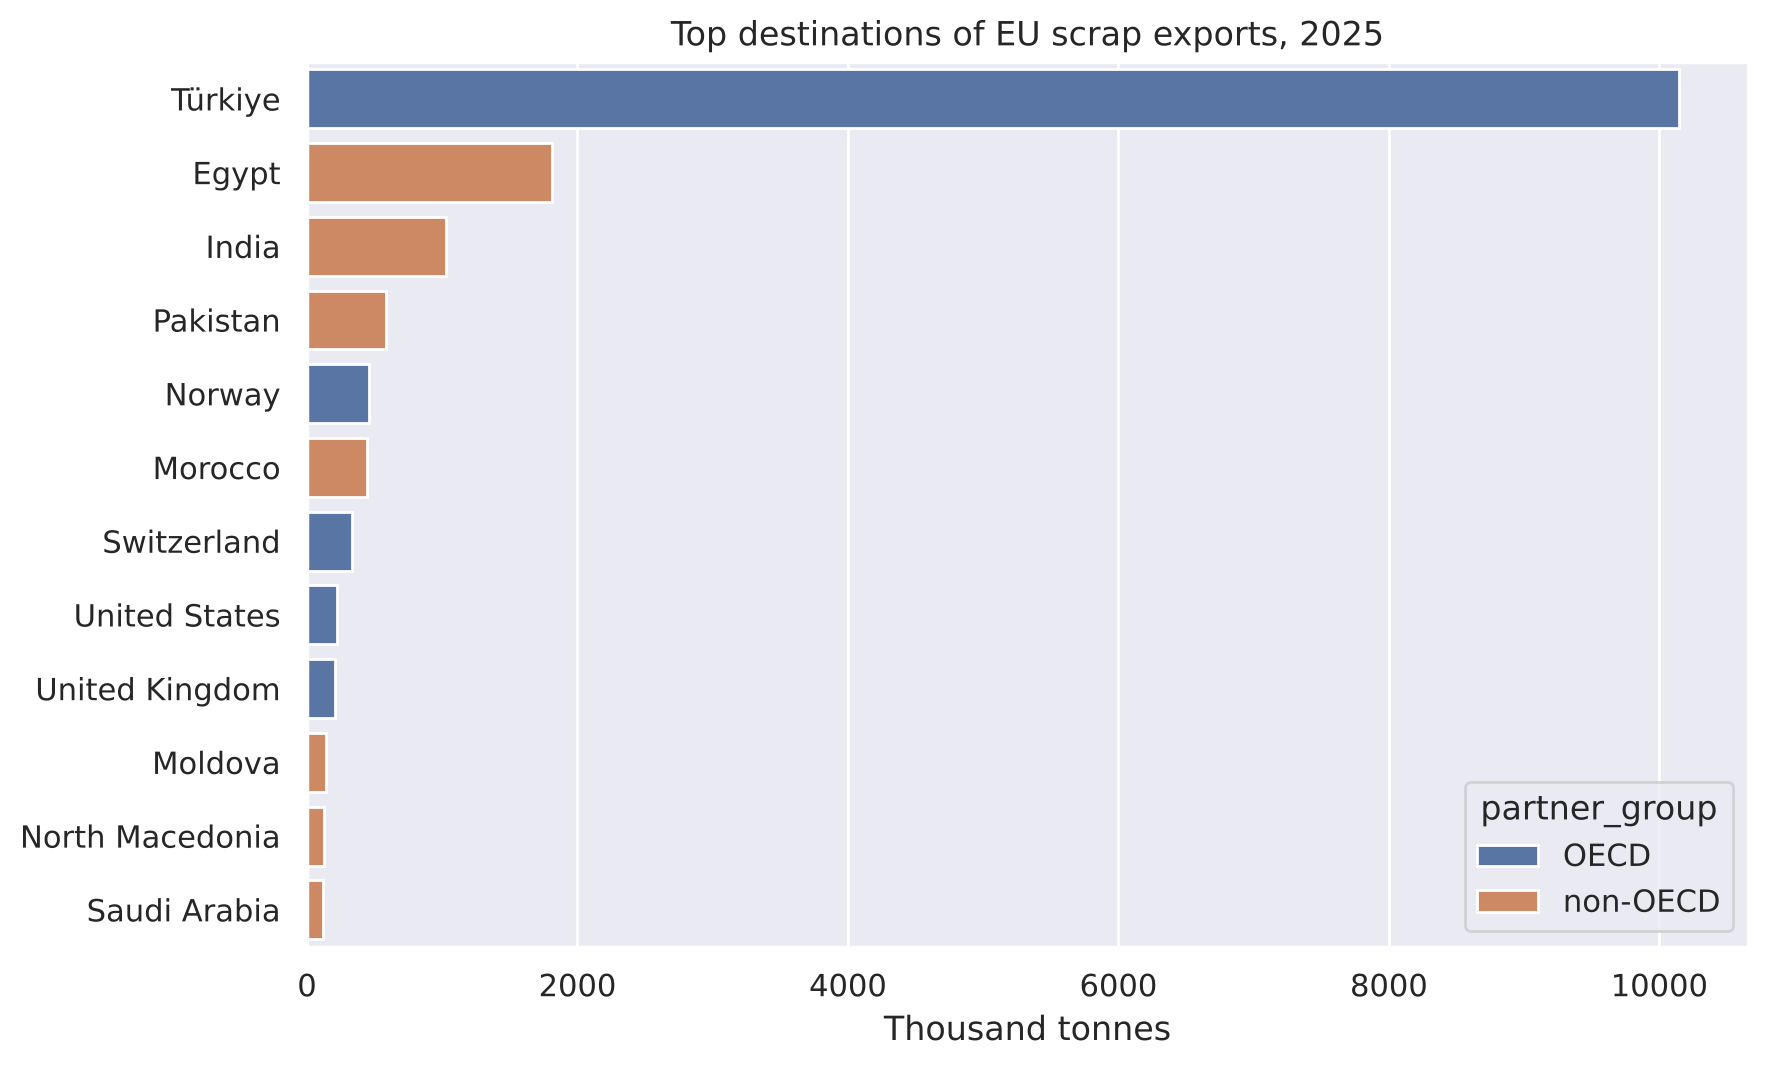

In [12]:
plt.figure(figsize=(9, 5.5))
sns.barplot(data=dest.head(12), x='kt', y='partner_name', hue='partner_group', dodge=False)
plt.title('Top destinations of EU scrap exports, 2025')
plt.xlabel('Thousand tonnes')
plt.ylabel('')
plt.tight_layout()
plt.savefig('../outputs/figures/02_destinations_2025.png')
plt.show()

### Jan-Sep 2026 vs Jan-Sep 2025

In [13]:
jan_sep = exp[(exp['year'].isin([2025, 2026])) & (exp['date'].dt.month <= 9)]

ytd = jan_sep.pivot_table(index='partner_group', columns='year', values='tonnes', aggfunc='sum') / 1e6
ytd['change_pct'] = 100 * (ytd[2026] / ytd[2025] - 1)
ytd

year,2025,2026,change_pct
partner_group,,,
OECD,8.406794,9.104879,8.303818
non-OECD,2.902203,3.416617,17.724952


In [14]:
ytd_country = jan_sep.pivot_table(index='partner_name', columns='year', values='tonnes', aggfunc='sum') / 1e3
ytd_country['change_pct'] = 100 * (ytd_country[2026] / ytd_country[2025] - 1)
ytd_country.sort_values(2025, ascending=False).head(10)

year,2025,2026,change_pct
partner_name,,,
Türkiye,7381.521077,7983.849262,8.159947
Egypt,1165.436708,1330.093479,14.128332
India,747.672298,648.329302,-13.286970
Pakistan,382.171395,609.446226,59.469346
Norway,355.423210,348.866402,-1.844789
Switzerland,280.003306,233.674787,-16.545704
Morocco,266.175233,534.968965,100.983750
United States,219.176717,338.802845,54.579761
United Kingdom,168.191770,195.178823,16.045406


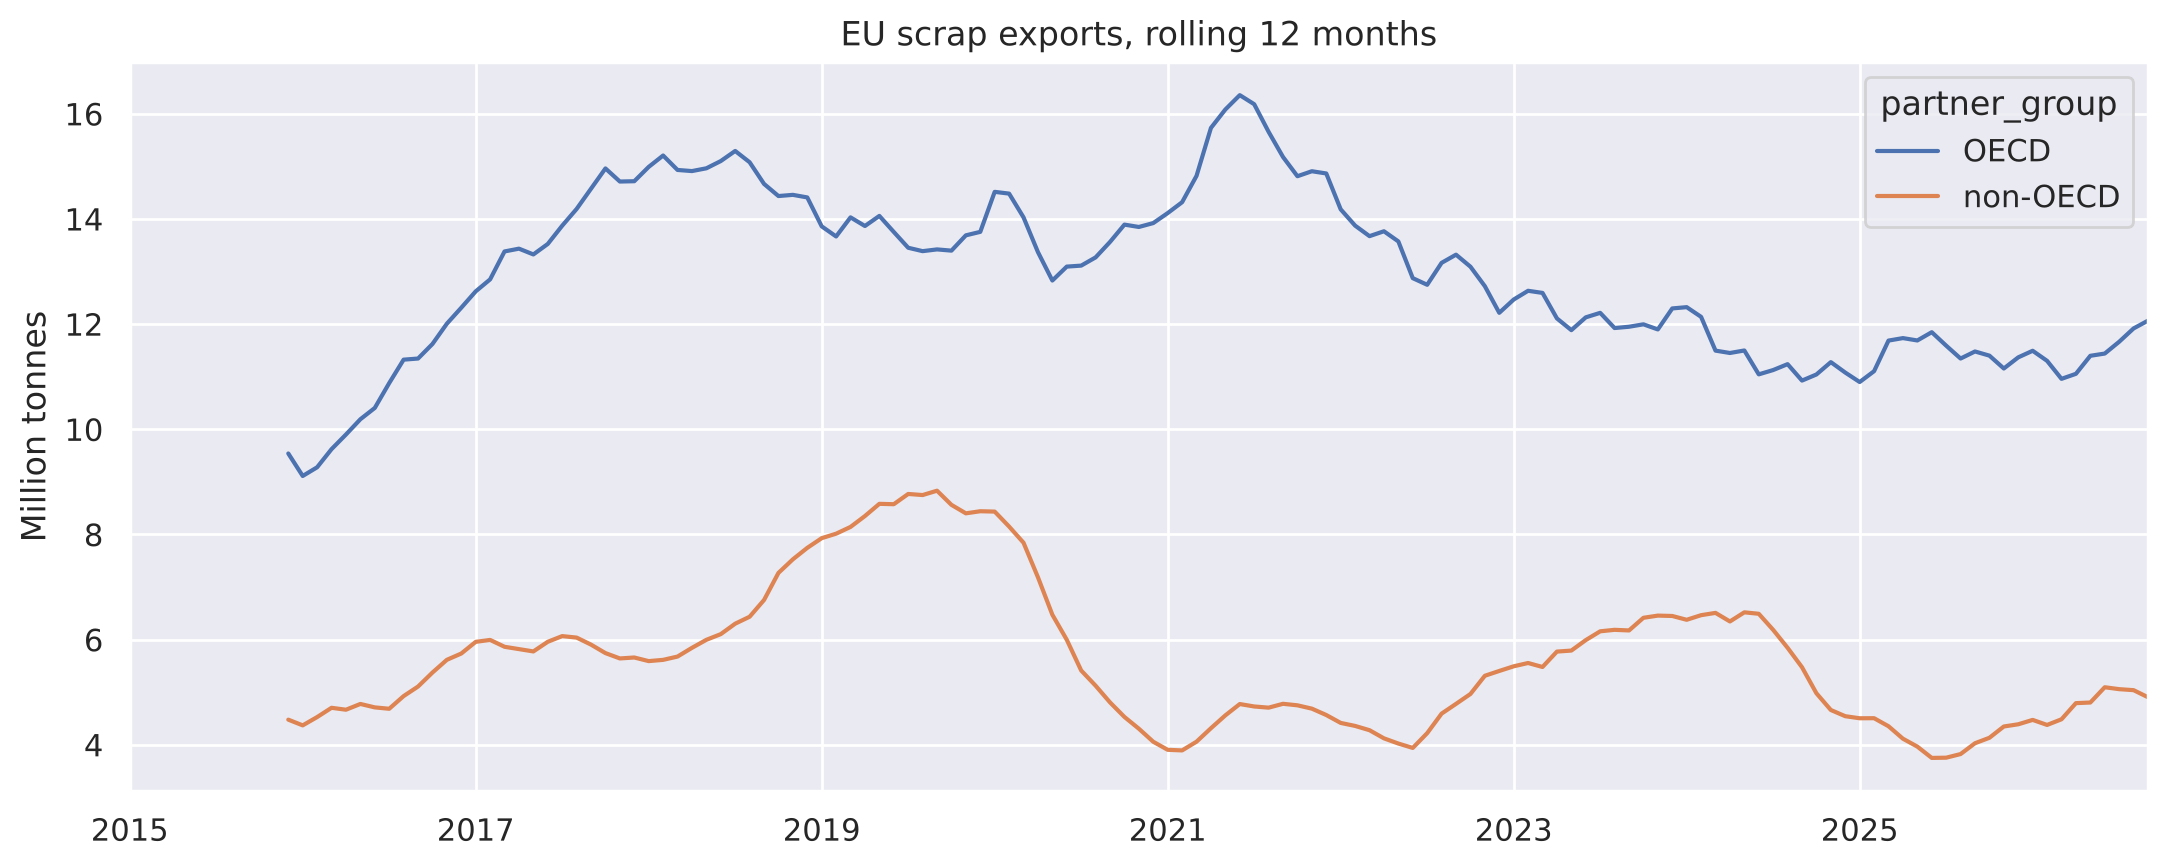

In [15]:
m = exp.pivot_table(index='date', columns='partner_group', values='tonnes', aggfunc='sum')
roll = m.rolling(12).sum() / 1e6

roll.plot(figsize=(11, 4.5))
plt.title('EU scrap exports, rolling 12 months')
plt.ylabel('Million tonnes')
plt.xlabel('')
plt.tight_layout()
plt.savefig('../outputs/figures/03_exports_rolling.png')
plt.show()

### Scrap grades exported in 2025

In [16]:
url = 'https://ec.europa.eu/eurostat/api/comext/dissemination/sdmx/2.1/data/DS-045409/M.EU.EXT_EU.720410+720421+720429+720430+720441+720449+720450.2.QUANTITY_IN_100KG+VALUE_IN_EUROS?format=SDMX-CSV&startPeriod=2025-01&endPeriod=2025-12'
grades = pd.read_csv(url, dtype={'product': str})
grades = grades.pivot_table(index='product', columns='indicators', values='OBS_VALUE', aggfunc='sum')
grades['kt'] = grades['QUANTITY_IN_100KG'] * 0.1 / 1e3
grades['share_pct'] = 100 * grades['kt'] / grades['kt'].sum()
grades['eur_per_t'] = grades['VALUE_IN_EUROS'] / (grades['kt'] * 1e3)
grades.index = grades.index.map({'720410': 'Cast iron', '720421': 'Stainless', '720429': 'Other alloy', '720430': 'Tinned',
                                 '720441': 'Turnings', '720449': 'Other (HMS, shredded)', '720450': 'Remelting ingots'})
grades[['kt', 'share_pct', 'eur_per_t']].sort_values('kt', ascending=False)

indicators,kt,share_pct,eur_per_t
product,,,
"Other (HMS, shredded)",13866.275595,88.019848,311.245866
Other alloy,793.120661,5.034543,347.890587
Turnings,597.174955,3.790726,313.408589
Stainless,205.748899,1.306045,1324.211548
Tinned,153.150094,0.972161,288.596669
Cast iron,137.663966,0.873858,337.789687
Remelting ingots,0.444040,0.002819,2024.601387


### Prices
unit value = euros / tonnes

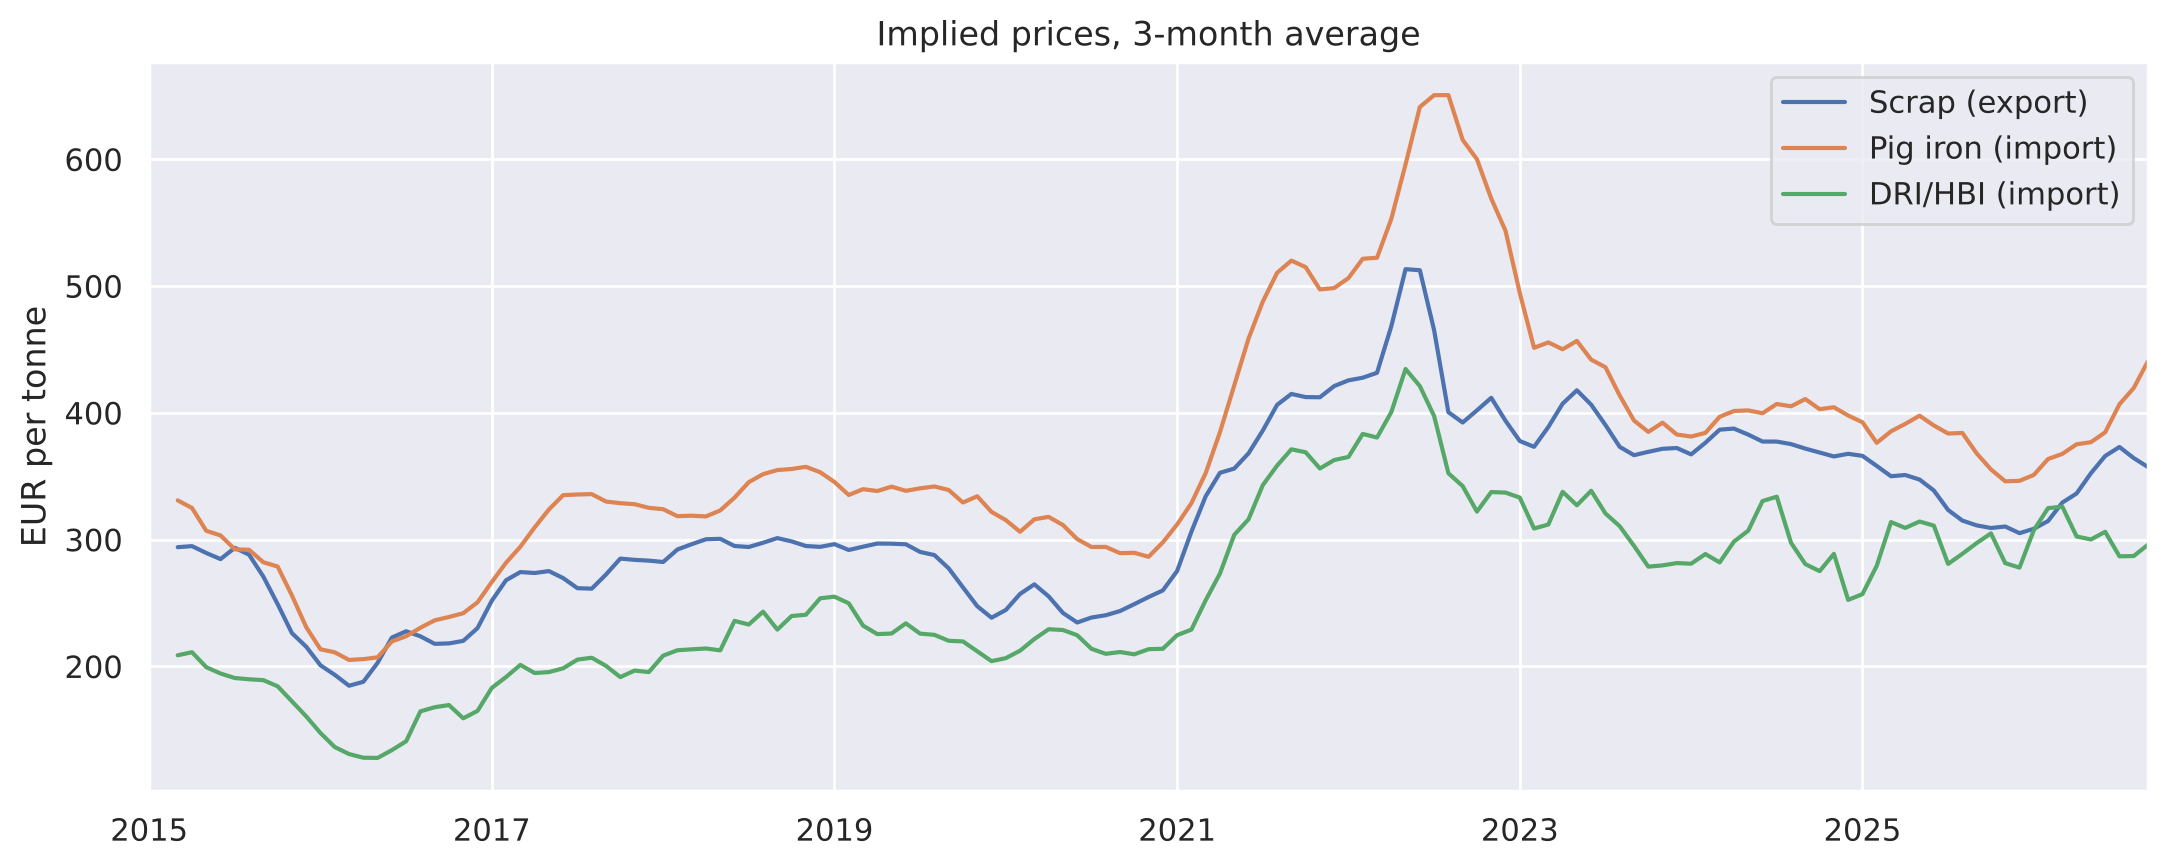

,Scrap (export),Pig iron (import),DRI/HBI (import)
Scrap (export),1.000000,0.899501,0.876574
Pig iron (import),0.899501,1.000000,0.857997
DRI/HBI (import),0.876574,0.857997,1.000000


In [17]:
ext = trade[trade['partner'] == 'EXT_EU']
uv = DataFrame({
    'Scrap (export)': ext[(ext['product'] == '7204') & (ext['flow'] == 'export')].groupby('date')[['eur', 'tonnes']].sum().eval('eur / tonnes'),
    'Pig iron (import)': ext[(ext['product'] == '7201') & (ext['flow'] == 'import')].groupby('date')[['eur', 'tonnes']].sum().eval('eur / tonnes'),
    'DRI/HBI (import)': ext[(ext['product'] == '720310') & (ext['flow'] == 'import')].groupby('date')[['eur', 'tonnes']].sum().eval('eur / tonnes')})

uv.rolling(3).mean().plot(figsize=(11, 4.5))
plt.title('Implied prices, 3-month average')
plt.ylabel('EUR per tonne')
plt.xlabel('')
plt.tight_layout()
plt.savefig('../outputs/figures/04_unit_values.png')
plt.show()

uv.corr()

### Net scrap position of each member state, 2025

In [18]:
url = 'https://ec.europa.eu/eurostat/api/comext/dissemination/sdmx/2.1/data/DS-045409/A.AT+BE+BG+CY+CZ+DE+DK+EE+ES+FI+FR+GR+HR+HU+IE+IT+LT+LU+LV+MT+NL+PL+PT+RO+SE+SI+SK.EXT_EU+INT_EU.7204.1+2.QUANTITY_IN_100KG?format=SDMX-CSV&startPeriod=2025&endPeriod=2025'
ms = pd.read_csv(url, dtype={'flow': str})
ms['mt'] = ms['OBS_VALUE'] * 0.1 / 1e6
ms = ms.pivot_table(index='reporter', columns=['partner', 'flow'], values='mt', aggfunc='sum').fillna(0)

net = DataFrame({'net_extra_eu_mt': ms[('EXT_EU', '2')] - ms[('EXT_EU', '1')],
                 'net_intra_eu_mt': ms[('INT_EU', '2')] - ms[('INT_EU', '1')]})
net['net_total_mt'] = net['net_extra_eu_mt'] + net['net_intra_eu_mt']
net['partner_name'] = net.index.map(names)
net = net.sort_values('net_total_mt')
net

,net_extra_eu_mt,net_intra_eu_mt,net_total_mt,partner_name
reporter,,,,
IT,-0.424300,-5.467183,-5.891484,Italy
ES,-0.664224,-2.358113,-3.022337,Spain
LU,-0.017493,-1.788452,-1.805945,Luxembourg
PT,-0.412379,-0.568284,-0.980663,Portugal
GR,-0.484483,-0.196101,-0.680584,Greece
SI,-0.057957,0.009696,-0.048260,Slovenia
BE,2.454885,-2.489323,-0.034438,Belgium
MT,0.032395,0.002263,0.034657,Malta
CY,0.018073,0.080990,0.099063,Cyprus


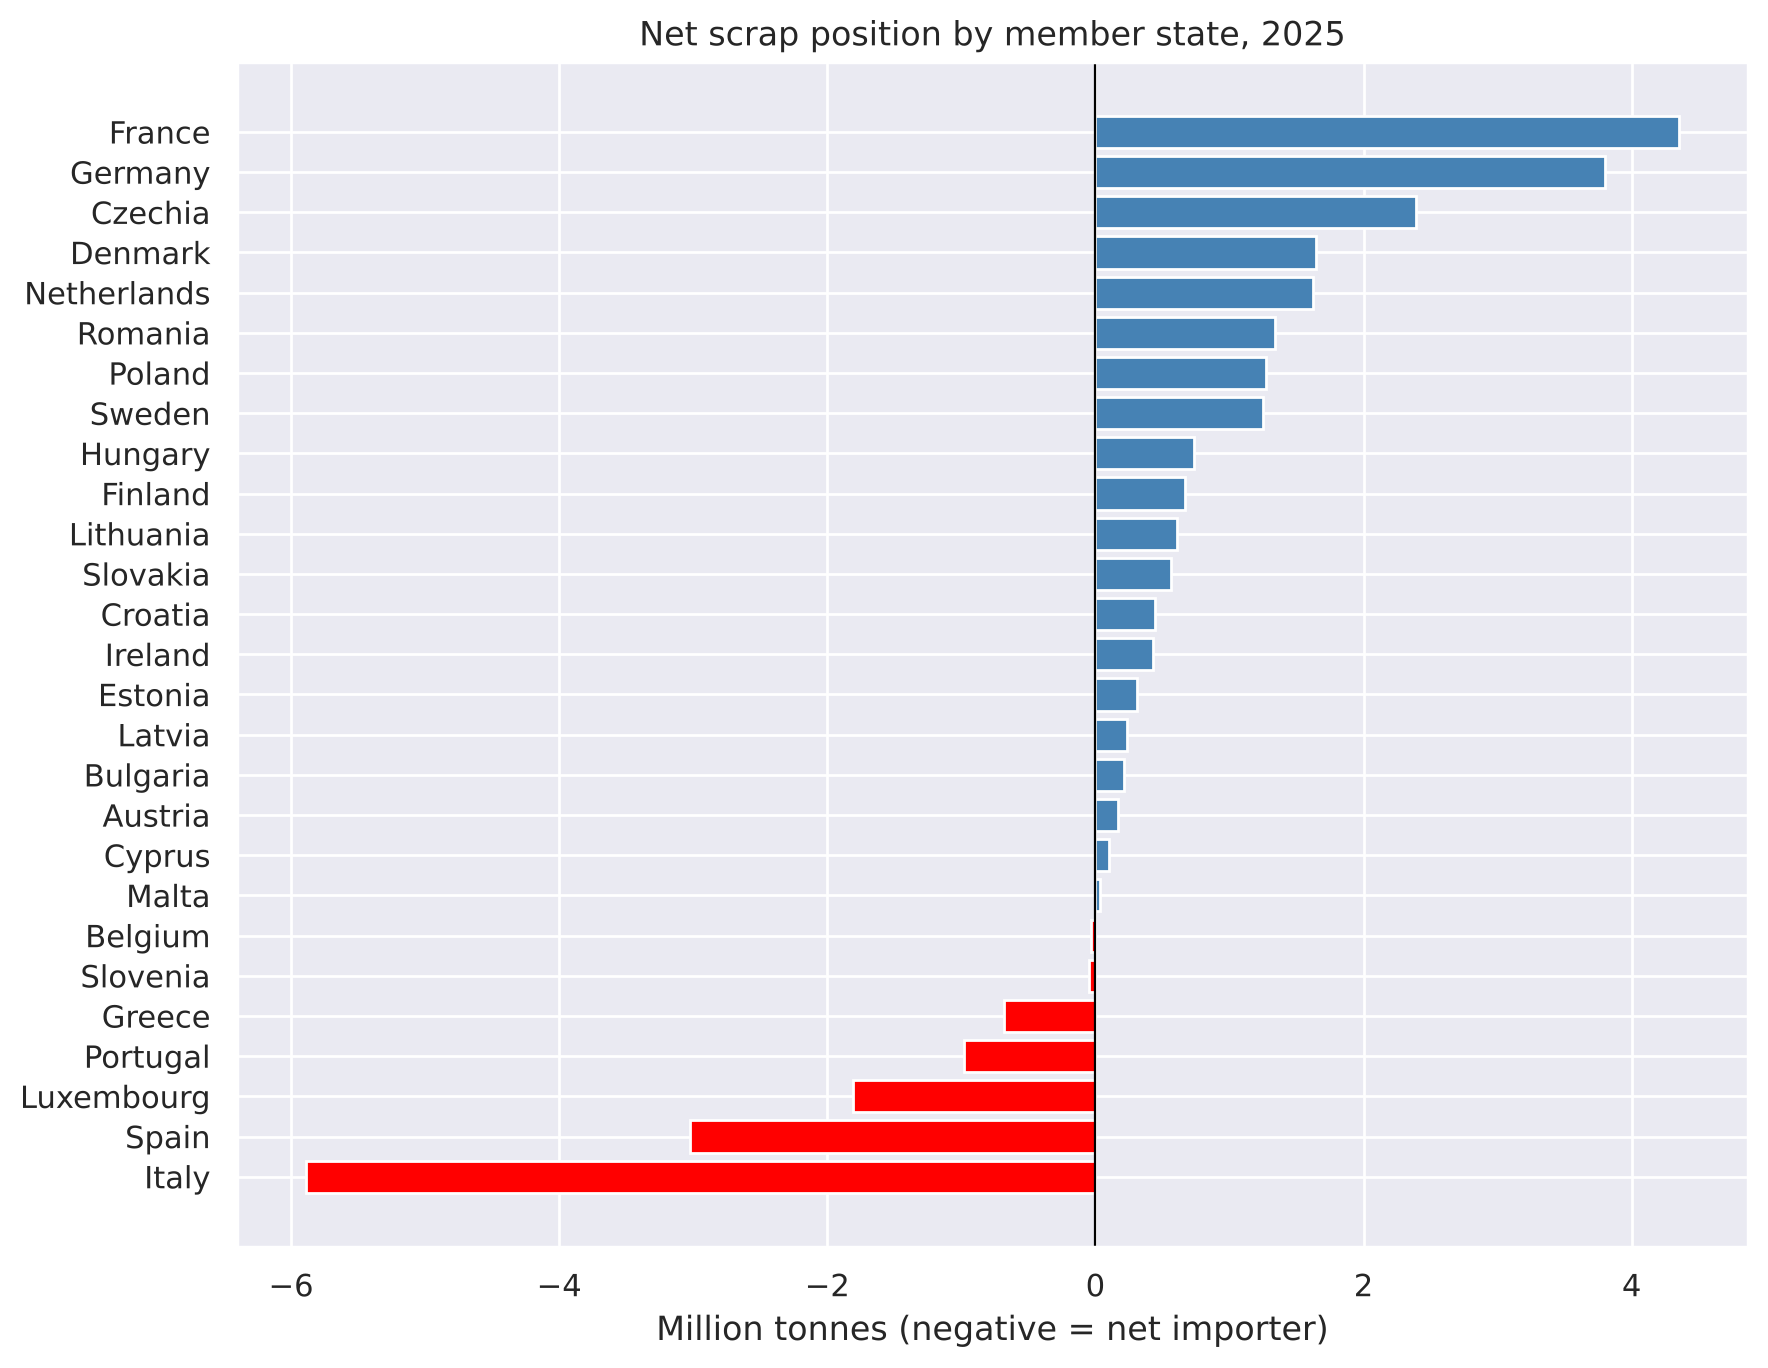

In [19]:
plt.figure(figsize=(9, 7))
colors = ['red' if x < 0 else 'steelblue' for x in net['net_total_mt']]
plt.barh(net['partner_name'], net['net_total_mt'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Net scrap position by member state, 2025')
plt.xlabel('Million tonnes (negative = net importer)')
plt.tight_layout()
plt.savefig('../outputs/figures/05_member_states.png')
plt.show()

### Where pig iron and DRI come from

In [20]:
imp = trade[(trade['flow'] == 'import') & (trade['product'].isin(['7201', '720310'])) & (trade['partner_group'].isin(['OECD', 'non-OECD']))]

subs = imp[imp['year'] == 2025].groupby(['product_name', 'partner_name'])[['tonnes', 'eur']].sum().reset_index()
subs['kt'] = subs['tonnes'] / 1e3
subs['share_pct'] = 100 * subs['tonnes'] / subs.groupby('product_name')['tonnes'].transform('sum')
subs['eur_per_t'] = subs['eur'] / subs['tonnes']
subs = subs.sort_values(['product_name', 'kt'], ascending=[True, False]).groupby('product_name').head(6)
subs[['product_name', 'partner_name', 'kt', 'share_pct', 'eur_per_t']]

,product_name,partner_name,kt,share_pct,eur_per_t
16,DRI / HBI,Venezuela,627.571705,27.757490,295.670339
10,DRI / HBI,Russia,584.661727,25.859582,300.238203
15,DRI / HBI,United States,494.373299,21.866126,347.083437
6,DRI / HBI,Libya,361.601837,15.993645,245.732798
0,DRI / HBI,Algeria,98.232305,4.344814,176.195988
9,DRI / HBI,Qatar,72.354946,3.200258,319.185298
29,Pig iron,Russia,699.991809,27.866202,365.262474
38,Pig iron,Ukraine,566.768609,22.562677,368.861898
17,Pig iron,Brazil,500.150840,19.910668,397.149368
32,Pig iron,South Africa,401.912900,15.999882,330.266752


In [21]:
ru = imp[imp['year'] >= 2022].copy()
ru['ru_tonnes'] = np.where(ru['partner'] == 'RU', ru['tonnes'], 0)

russia = ru.groupby(['product_name', 'year'])[['tonnes', 'ru_tonnes']].sum()
russia['total_kt'] = russia['tonnes'] / 1e3
russia['russia_share_pct'] = 100 * russia['ru_tonnes'] / russia['tonnes']
russia[['total_kt', 'russia_share_pct']]

total_kt  russia_share_pct
product_name year                               
DRI / HBI    2022  2927.191019         51.588786
             2023  2580.753575         46.033959
             2024  2743.936010         38.021791
             2025  2260.909437         25.859582
             2026  1006.287526          0.000000
Pig iron     2022  2443.048758         47.973838
             2023  2405.816894         58.519033
             2024  2161.285083         47.655483
             2025  2511.974174         27.866202
             2026   836.969538          0.000000

## Save for Power BI

In [22]:
trade.to_csv('../data/processed/fact_trade_monthly.csv', index=False)
balance.to_csv('../data/processed/scrap_balance_annual.csv', index=False)
net.reset_index().rename(columns={'reporter': 'member_state'}).to_csv('../data/processed/member_state_net_2025.csv', index=False)